# 04 - Model Evaluation

This notebook evaluates the selected production model using regression metrics, diagnostic plots, feature importance, and SHAP explanations. Run `03_Model_Training.ipynb` or `python src/train.py` before executing this notebook.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import shap
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_preprocessing import prepare_model_data
from src.evaluate import (
    calculate_regression_metrics,
    calculate_shap_values,
    extract_feature_importance,
    get_feature_names_from_preprocessor,
    plot_actual_vs_predicted,
    plot_feature_importance,
    plot_learning_curve,
    plot_prediction_error_distribution,
    plot_residuals,
    plot_shap_summary,
    plot_shap_waterfall,
    plot_validation_curve,
)
from src.utils import (
    BEST_MODEL_PATH,
    FEATURE_IMPORTANCE_PATH,
    METRICS_PATH,
    PREPROCESSOR_PATH,
    RANDOM_STATE,
    load_joblib_artifact,
    load_json,
    load_raw_data,
)

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 100)

## Load Model Artifacts

In [2]:
model = load_joblib_artifact(BEST_MODEL_PATH)
preprocessor = load_joblib_artifact(PREPROCESSOR_PATH)
metrics_payload = load_json(METRICS_PATH)

print(f"Best model: {metrics_payload.get('best_model')}")
print(f"Model artifact: {BEST_MODEL_PATH}")
print(f"Preprocessor artifact: {PREPROCESSOR_PATH}")

Best model: CatBoost
Model artifact: C:\files\Desktop\code\car_price prediction\used-car-price-prediction\models\best_model.joblib
Preprocessor artifact: C:\files\Desktop\code\car_price prediction\used-car-price-prediction\models\preprocessor.joblib


**Evaluation note:** The model and preprocessing pipeline are loaded as separate artifacts. This mirrors deployment, where the API transforms incoming payloads before passing them to the trained estimator.

## Recreate Holdout Data

In [3]:
raw_data = load_raw_data()
features, target, _ = prepare_model_data(raw_data)

features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

transformed_train = preprocessor.transform(features_train)
transformed_test = preprocessor.transform(features_test)
feature_names = get_feature_names_from_preprocessor(preprocessor)

transformed_train_frame = pd.DataFrame(transformed_train, columns=feature_names)
transformed_test_frame = pd.DataFrame(transformed_test, columns=feature_names)

predictions = model.predict(transformed_test_frame)
evaluation_metrics = calculate_regression_metrics(target_test, predictions)

display(pd.DataFrame([evaluation_metrics]))

,r2,mae,rmse,mape,median_absolute_error,explained_variance
0,0.898697,0.692042,1.174788,25.744631,0.392861,0.903563


**Business insight:** These metrics estimate pricing accuracy on unseen cars. MAE gives an operationally intuitive average miss in INR lakhs, while RMSE penalizes large pricing errors more heavily.

## Model Comparison Table

In [4]:
comparison_table = pd.DataFrame(metrics_payload.get("model_comparison", []))
display(comparison_table)

,model,r2,mae,rmse,mape,median_absolute_error,explained_variance,cv_rmse_mean,cv_rmse_std
0,CatBoost,0.898697,0.692042,1.174788,25.744631,0.392861,0.903563,0.852612,0.252316
1,CatBoost Tuned,0.871467,0.707180,1.323291,24.934250,0.329245,0.879675,0.781912,0.146776
2,LightGBM Tuned,0.853098,0.923584,1.414693,41.994631,0.567949,0.868190,1.003101,0.238321
3,LightGBM,0.852462,0.900738,1.417752,40.986766,0.442979,0.866451,1.022253,0.270480
4,XGBoost Tuned,0.835006,0.758303,1.499277,23.890338,0.279103,0.845869,0.740026,0.166024
5,XGBoost,0.733281,0.873739,1.906227,29.122172,0.252073,0.748266,0.768609,0.197650
6,Gradient Boosting,0.723884,0.920962,1.939518,29.377871,0.273801,0.748765,0.788327,0.164181
7,Random Forest,0.697604,0.957822,2.029718,30.372361,0.378592,0.716926,0.772307,0.212343
8,Linear Regression,0.695304,1.203092,2.037423,129.573272,0.796331,0.706321,1.178147,0.177060
9,Decision Tree,0.582147,1.050083,2.385942,36.795687,0.250000,0.610007,0.925225,0.175045


**Business insight:** Comparing multiple model families prevents overcommitting to a single algorithm. The final selection should balance validation stability, holdout accuracy, inference cost, and explainability.

## Actual vs Predicted

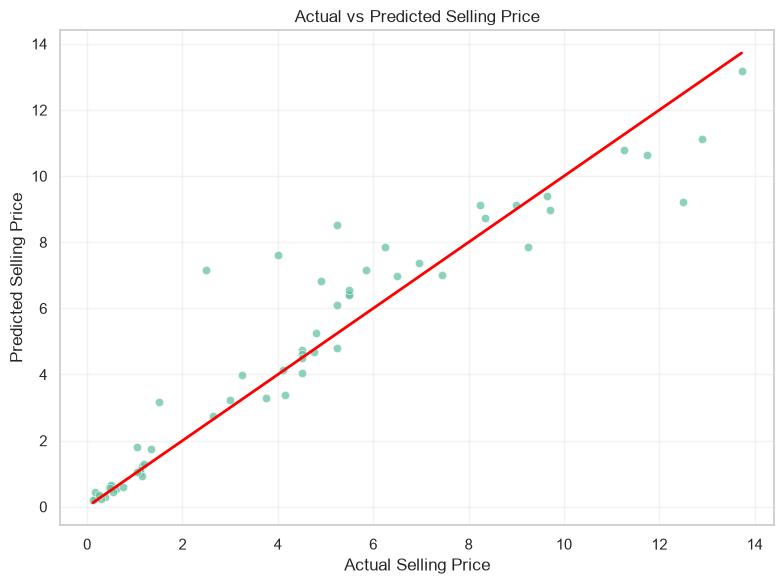

In [5]:
plot_actual_vs_predicted(target_test, predictions)
plt.show()

**Business insight:** Points close to the diagonal represent accurate price estimates. Large deviations should be investigated by vehicle segment, fuel type, transmission, and kilometer profile.

## Residual Plot

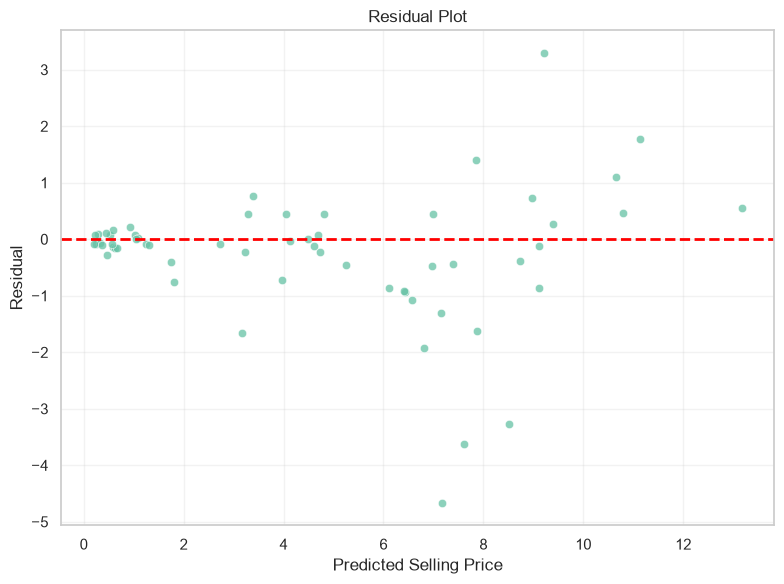

In [6]:
plot_residuals(target_test, predictions)
plt.show()

**Business insight:** Residuals should be centered around zero. A visible pattern may indicate that the model systematically overprices or underprices certain vehicle segments.

## Prediction Error Distribution

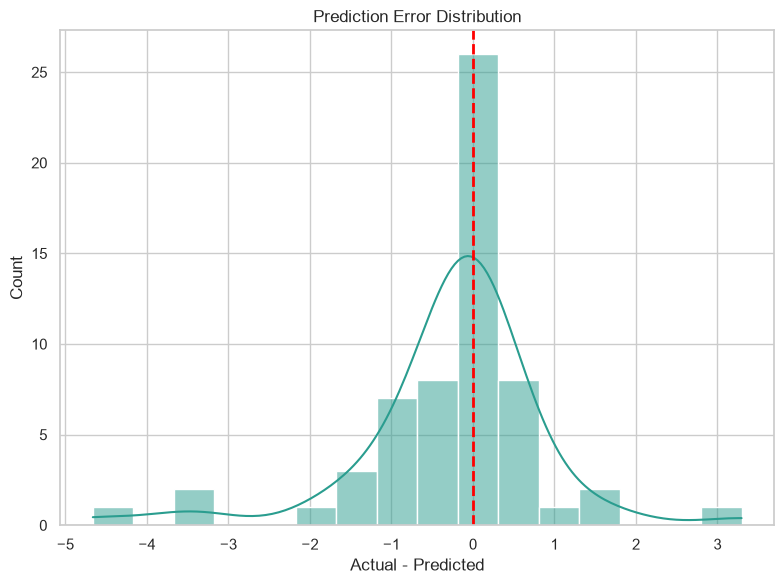

In [7]:
plot_prediction_error_distribution(target_test, predictions)
plt.show()

**Business insight:** A narrow error distribution around zero is desirable. Long tails are important because even a small number of large pricing errors can damage marketplace margin or conversion.

## Learning Curve

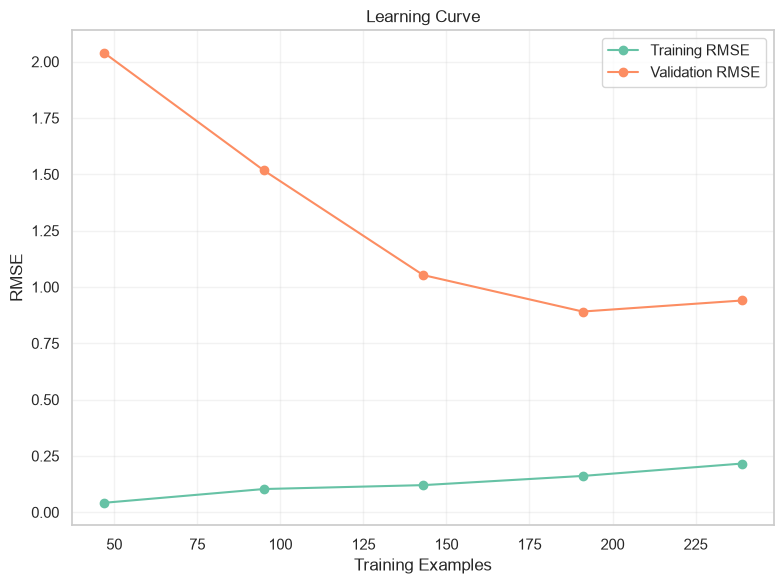

In [8]:
evaluation_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ]
)

plot_learning_curve(evaluation_pipeline, features, target, cv=5)
plt.show()

**Business insight:** Learning curves show whether the model would likely benefit from more data. If training and validation errors remain far apart, the model may be overfitting; if both are high, better features may be needed.

## Validation Curve

In [9]:
if hasattr(model, "max_depth"):
    parameter_name = "model__max_depth"
    parameter_range = [2, 3, 4, 5, 6, 8, 10]
elif hasattr(model, "n_estimators"):
    parameter_name = "model__n_estimators"
    parameter_range = [50, 100, 200, 300, 500]
else:
    parameter_name = None

if parameter_name:
    plot_validation_curve(
        evaluation_pipeline,
        features,
        target,
        parameter_name=parameter_name,
        parameter_range=parameter_range,
        cv=5,
    )
    plt.show()
else:
    print("Validation curve skipped because no simple supported hyperparameter was detected.")

Validation curve skipped because no simple supported hyperparameter was detected.


**Business insight:** Validation curves help identify whether extra complexity improves generalization or only memorizes training examples. This supports defensible model selection in portfolio and production settings.

## Feature Importance

,feature,importance
0,log_present_price,32.198351
1,present_price,24.024365
2,year,9.337296
3,seller_type_Dealer,5.810641
4,car_age,3.243249
5,vehicle_age_bucket_12+ years,2.666056
6,seller_type_Individual,2.649637
7,log_driven_km,2.613128
8,price_segment_luxury,2.466099
9,price_segment_mid_market,2.393062


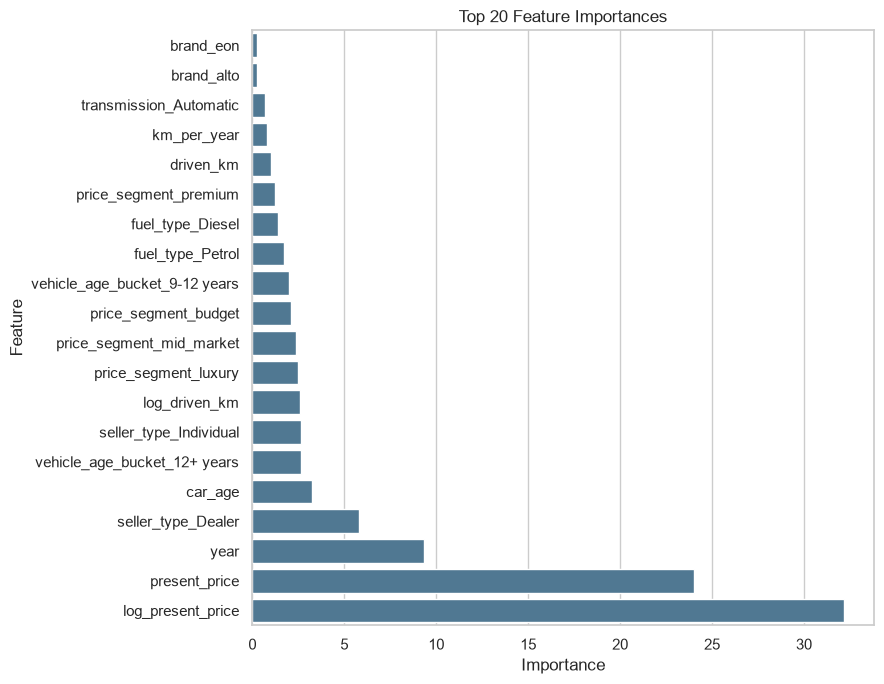

In [10]:
if FEATURE_IMPORTANCE_PATH.exists():
    feature_importance = pd.read_csv(FEATURE_IMPORTANCE_PATH)
else:
    feature_importance = extract_feature_importance(
        model,
        feature_names,
        transformed_train_frame,
        target_train,
    )

display(feature_importance.head(20))
plot_feature_importance(feature_importance, top_n=20)
plt.show()

**Business insight:** Feature importance explains which listing attributes most influence predicted resale price. Present price, car age, kilometers, and segment-related variables are usually expected to dominate.

## SHAP Summary Plot

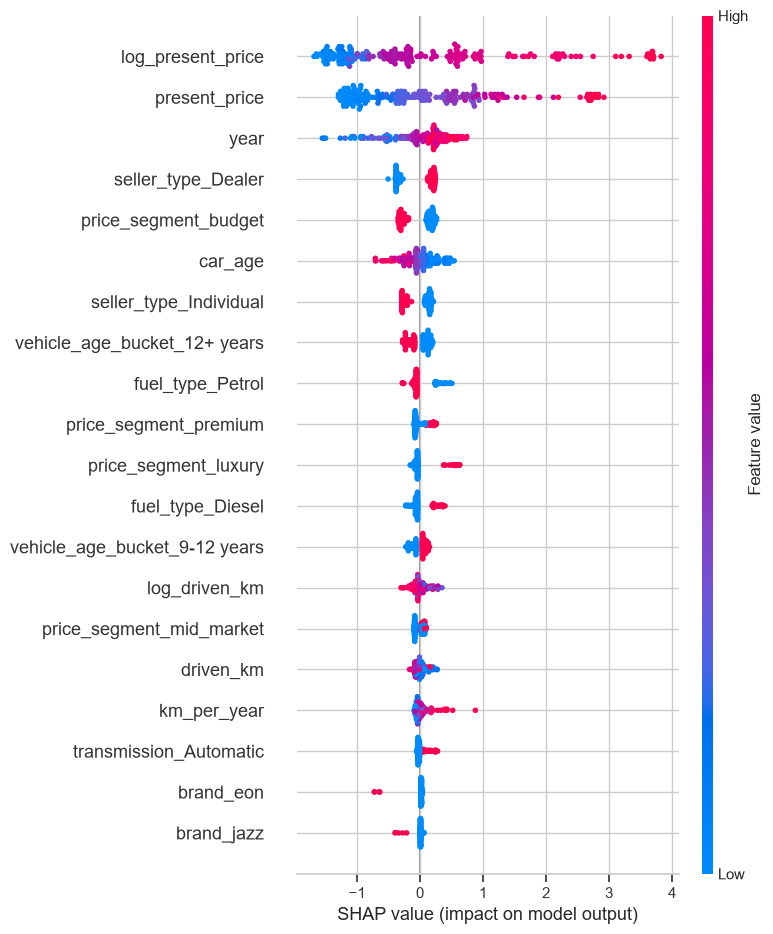

In [11]:
shap_values, shap_sample = calculate_shap_values(model, transformed_train_frame, max_rows=200)
plot_shap_summary(shap_values, shap_sample)
plt.show()

**Business insight:** The SHAP summary plot shows both feature importance and direction. It helps answer not only which features matter, but whether higher or lower values push predicted price up or down.

## SHAP Waterfall Plot

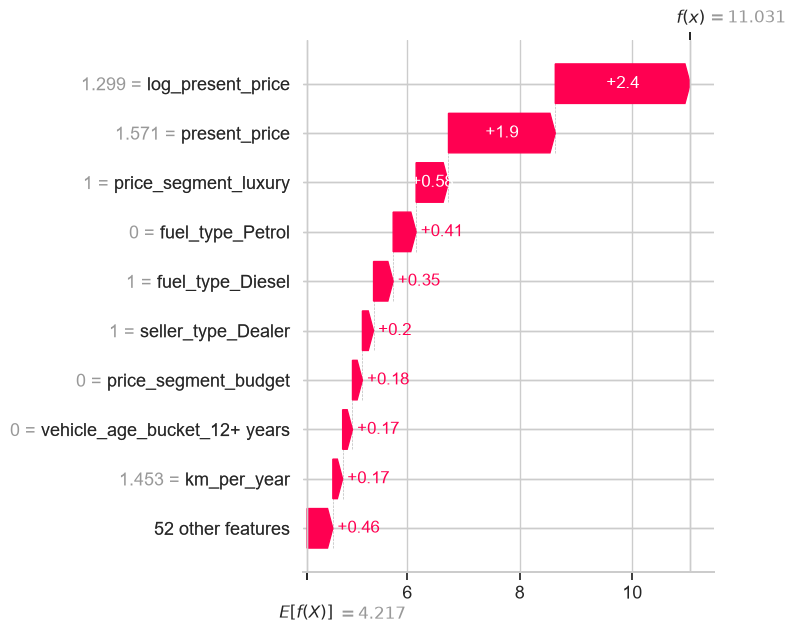

In [12]:
plot_shap_waterfall(shap_values, row_index=0)
plt.show()

**Business insight:** The waterfall plot explains one prediction by showing how individual features move the estimate away from the model baseline. This is useful for seller-facing price justification.

## SHAP Force Plot

In [13]:
shap.initjs()
first_explanation = shap_values[0]
shap.plots.force(first_explanation)

**Business insight:** The force plot provides an interactive local explanation. Features pushing the price higher and lower can be reviewed in a compact format for pricing analysts or marketplace operations teams.

## Segment-Level Error Review

In [14]:
error_frame = features_test.copy()
error_frame["actual_price"] = target_test.values
error_frame["predicted_price"] = predictions
error_frame["absolute_error"] = (error_frame["actual_price"] - error_frame["predicted_price"]).abs()

segment_error = (
    error_frame.groupby("price_segment", observed=False)
    .agg(
        listings=("absolute_error", "size"),
        mae=("absolute_error", "mean"),
        median_error=("absolute_error", "median"),
        avg_actual_price=("actual_price", "mean"),
    )
    .sort_values("mae", ascending=False)
)
display(segment_error)

,listings,mae,median_error,avg_actual_price
price_segment,,,,
luxury,7,2.016053,1.308614,6.846429
premium,19,1.039440,0.916663,7.649474
mid_market,13,0.392668,0.446036,3.900000
budget,21,0.121719,0.089490,0.645714


**Business insight:** Segment-level error review is critical for marketplace deployment. A model can look strong overall while still underperforming on premium vehicles or sparse segments.

## Evaluation Takeaways

- The final model is evaluated with both aggregate metrics and diagnostic plots.
- Actual-vs-predicted and residual plots help identify systematic pricing errors.
- Learning and validation curves support model capacity decisions.
- Feature importance and SHAP make the model more interpretable for business stakeholders.
- Segment-level error analysis prepares the model for marketplace-style monitoring after deployment.